<a href="https://colab.research.google.com/github/karthirajamanikam-2003/Rigel/blob/main/langauage%20identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Saving dataset.csv to dataset.csv
Dataset shape: (22000, 2)
Columns: ['Text', 'language']
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch


In [ ]:
# Automatically detect text and language columns
column_map = {str(c).strip().lower(): c for c in df.columns}

text_col = next(
    (column_map[c] for c in ["text", "text_sample", "sentence"]
     if c in column_map),
    None
)

label_col = next(
    (column_map[c] for c in ["language", "label", "lang"]
     if c in column_map),
    None
)

if text_col is None or label_col is None:
    raise ValueError(
        f"Cannot identify columns. Available columns: {df.columns.tolist()}"
    )

df = df[[text_col, label_col]].copy()
df.columns = ["Text", "language"]

# Handle missing values
df = df.dropna(subset=["Text", "language"])

# Convert values to strings and remove empty rows
df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[
    (df["Text"] != "") &
    (df["language"] != "")
].drop_duplicates(subset=["Text", "language"])

# Basic text preprocessing
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["Text"] = df["Text"].apply(clean_text)

# Use a manageable subset
df = df.sample(
    n=min(10000, len(df)),
    random_state=42
).reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nLanguage counts:")
print(df["language"].value_counts())
print("\nSample records:")
print(df.head())

Cleaned dataset shape: (10000, 2)

Language counts:
language
Latin         496
Korean        474
English       473
Estonian      471
Turkish       470
Romanian      465
Spanish       464
Thai          463
Persian       461
Indonesian    459
Swedish       456
Arabic        454
Russian       452
Dutch         449
Japanese      446
French        444
Urdu          442
Portugese     441
Tamil         436
Hindi         435
Chinese       428
Pushto        421
Name: count, dtype: int64

Sample records:
                                                Text    language
0  semua kucing dalam genus ini berbagi nenek moy...  Indonesian
1  முதுகுநாண் என்பது கரு நிலையில் எல்லா முதுகுநாண...       Tamil
2  noile cerințe pentru sistemul existent au cond...    Romanian
3  segmentul spațial este format dintr-o constela...    Romanian
4  石見での形勢が逆転した毛利は和睦を破棄し、永禄年（年）には出雲侵攻に乗り出し、西出雲国人三沢...    Japanese


In [ ]:
label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(df["language"])

X = df["Text"].values
y = df["label"].values

# Remove labels with fewer than 2 samples if present
counts = pd.Series(y).value_counts()
valid_labels = counts[counts >= 2].index

mask = np.isin(y, valid_labels)
X = X[mask]
y = y[mask]

# Re-encode after filtering
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(
    df.loc[mask, "language"].values
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of languages:", len(label_encoder.classes_))

Training samples: 8000
Testing samples: 2000
Number of languages: 22


In [ ]:
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Fit only on training data
tokenizer.fit_on_texts(X_train)

# Convert text into numerical sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Make all sequences the same length
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

num_classes = len(label_encoder.classes_)

print("Vocabulary size:", vocab_size)
print("Padded training shape:", X_train_pad.shape)
print("Padded testing shape:", X_test_pad.shape)

Vocabulary size: 20000
Padded training shape: (8000, 100)
Padded testing shape: (2000, 100)


In [ ]:
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(32, activation="relu"),

    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/step - accuracy: 0.1628 - loss: 2.7066 - val_accuracy: 0.4575 - val_loss: 1.9369
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 11s 100ms/step - accuracy: 0.4278 - loss: 1.7005 - val_accuracy: 0.7362 - val_loss: 1.1201
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 11s 97ms/step - accuracy: 0.6646 - loss: 1.0732 - val_accuracy: 0.8512 - val_loss: 0.6836
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 10s 90ms/step - accuracy: 0.8183 - loss: 0.6729 - val_accuracy: 0.9038 - val_loss: 0.4353
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 11s 101ms/step - accuracy: 0.8349 - loss: 0.5912 - val_accuracy: 0.8700 - val_loss: 0.4969
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 12s 103ms/step - accuracy: 0.8628 - loss: 0.4439 - val_accuracy: 0.8900 - val_loss: 0.3647
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 12s 107ms/step - accuracy: 0.8885 - loss: 0.3816 - val_accuracy: 0.9013 - val_loss: 0.3612
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 11s 100ms/step - accuracy: 0.9128 - loss: 0.2

In [ ]:
y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nDetailed Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

Accuracy : 0.8975 (89.75%)
Precision: 0.8992
Recall   : 0.8952
F1-score : 0.8865

Detailed Classification Report:

              precision    recall  f1-score   support

      Arabic       0.96      0.98      0.97        91
     Chinese       0.38      0.03      0.06        86
       Dutch       0.99      0.98      0.98        90
     English       0.85      0.97      0.91        95
    Estonian       0.94      0.89      0.92        94
      French       0.98      0.99      0.98        89
       Hindi       1.00      0.99      0.99        87
  Indonesian       0.98      0.92      0.95        92
    Japanese       0.48      0.87      0.62        89
      Korean       0.92      0.97      0.94        95
       Latin       0.95      0.92      0.93        99
     Persian       0.99      0.98      0.98        92
   Portugese       0.99      0.88      0.93        88
      Pushto       1.00      0.93      0.96        84
    Romanian       0.97      0.97      0.97        93
     Russian       0

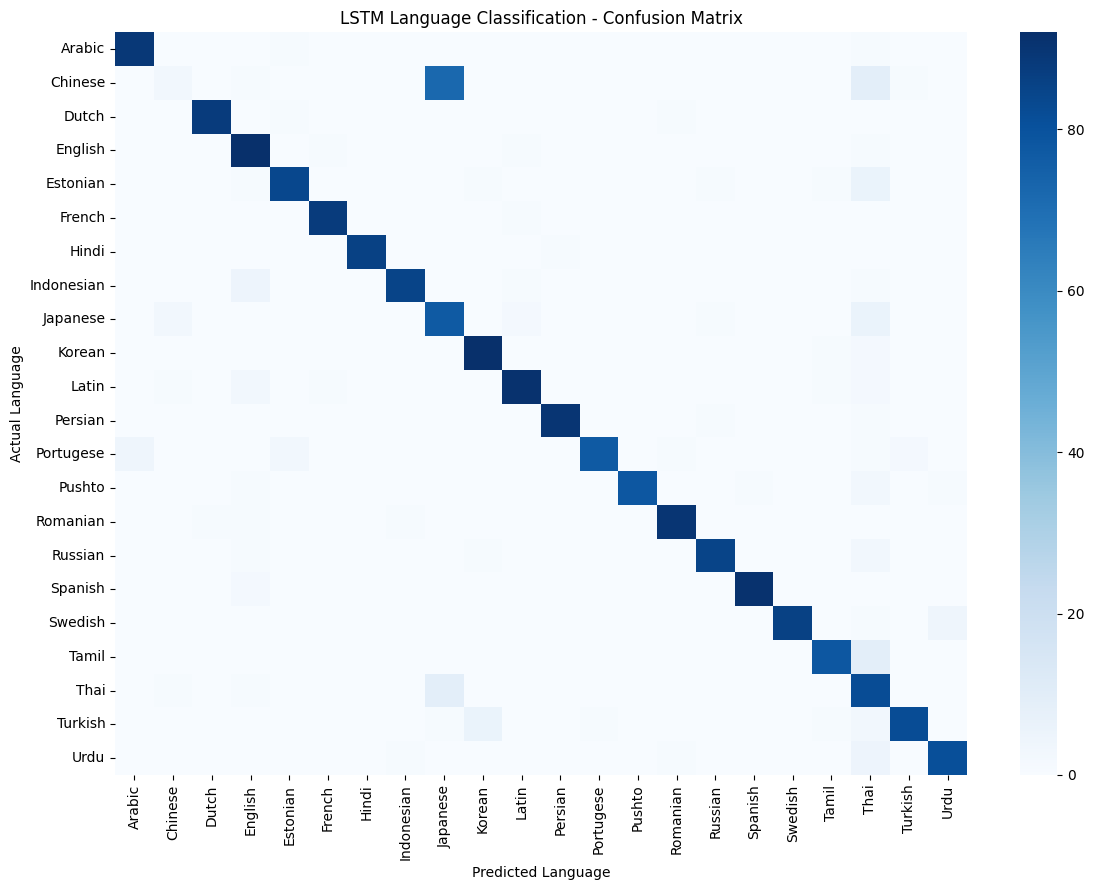

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    cmap="Blues",
    annot=(num_classes <= 15),
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("LSTM Language Classification - Confusion Matrix")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
def predict_language(text):
    cleaned = clean_text(text)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)[0]

    predicted_index = np.argmax(probabilities)
    predicted_language = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    confidence = probabilities[predicted_index] * 100

    return predicted_language, confidence


unseen_samples = [
    "Hello, how are you today?",
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?",
    "Bonjour, comment allez-vous?",
    "Hola, ¿cómo estás?",
    "Guten Morgen, wie geht es dir?"
]

for i, text in enumerate(unseen_samples, start=1):
    language, confidence = predict_language(text)

    print(f"\nSample {i}: {text}")
    print("Predicted language:", language)
    print(f"Confidence: {confidence:.2f}%")


Sample 1: Hello, how are you today?
Predicted language: Romanian
Confidence: 37.89%

Sample 2: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted language: Japanese
Confidence: 43.77%

Sample 3: Bonjour, comment allez-vous?
Predicted language: Japanese
Confidence: 43.77%

Sample 4: Hola, ¿cómo estás?
Predicted language: Japanese
Confidence: 46.16%

Sample 5: Guten Morgen, wie geht es dir?
Predicted language: Chinese
Confidence: 56.60%


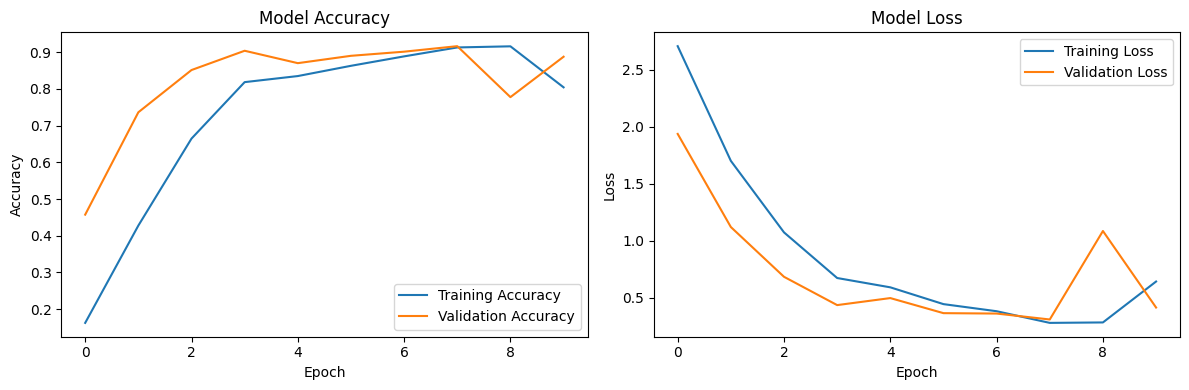

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
model.save("/content/lstm_language_model.keras")

import pickle

with open("/content/language_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("/content/language_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

print("Model and preprocessing objects saved successfully!")

Model and preprocessing objects saved successfully!
